# 02 - Preprocesamiento de Datos y Feature Engineering
**Proyecto Final: Minería de Datos (Grupo 1908)**
**Objetivo:** Limpiar el dataset, tratar outliers, manejar alta cardinalidad, crear nuevas variables, dividir en train/test (evitando data leakage) y guardar las versiones procesadas para los modelos posteriores.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import os

# Estilo de gráficas
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Crear carpeta processed si no existe
os.makedirs('../data/processed', exist_ok=True)

# Cargar dataset original
df = pd.read_csv('../data/raw/online_shoppers_intention.csv')
print("Shape original:", df.shape)

Shape original: (12330, 18)


## 1. Revisión de calidad y limpieza inicial
- **Valores faltantes:** En el EDA confirmamos que el dataset de UCI no tiene nulos. Lo re-verificamos por rigor.
- **Duplicados:** El dataset tiene ~125 filas duplicadas exactas. Dado que cada fila representa una sesión, duplicados exactos podrían ser errores de registro. Los eliminaremos.
- **Consistencia de tipos:** Variables como `OperatingSystems`, `Browser`, `Region` y `TrafficType` están guardadas como números (ej. 1, 2, 3), pero **son códigos categóricos nominales**. No tienen orden ni magnitud matemática. Las trataremos como texto/categorías para los siguientes pasos.

In [2]:
# 1. Verificar nulos
print("Total nulos antes:", df.isnull().sum().sum())

# 2. Eliminar duplicados
df_clean = df.drop_duplicates().copy()
print(f"Duplicados eliminados: {len(df) - len(df_clean)}")
print("Shape tras quitar duplicados:", df_clean.shape)

# 3. Convertir códigos numéricos a categóricos nominales
cols_categoricas_nominales = ['OperatingSystems', 'Browser', 'Region', 'TrafficType']
for col in cols_categoricas_nominales:
    df_clean[col] = df_clean[col].astype(str)

print("\nTipos de datos actualizados.")
df_clean[cols_categoricas_nominales].dtypes

Total nulos antes: 0
Duplicados eliminados: 125
Shape tras quitar duplicados: (12205, 18)

Tipos de datos actualizados.


OperatingSystems    str
Browser             str
Region              str
TrafficType         str
dtype: object

## 2. Tratamiento de Outliers (Winsorización + log1p)
Las variables de duración (`ProductRelated_Duration`, `Administrative_Duration`, `Informational_Duration`) presentan una **asimetría positiva severa** (cola larga a la derecha) y outliers extremos.

**¿Por qué combinar Winsorización (Percentil 99) + Log1p?**
1. **Winsorización:** Recortar al percentil 99 evita que sesiones extremas (bots o usuarios que dejaron la pestaña abierta) distorsionen los modelos, sin perder la sesión completa (no borramos filas).
2. **Log1p:** Aplicar el logaritmo después de recortar reduce la asimetría. Esto es vital para modelos sensibles a distancias o linealidad (como SVM, Regresión Lineal o K-Means).
*Nota: Usaremos `log1p` (log(1+x)) para evitar errores matemáticos con los valores 0 (que abundan).*

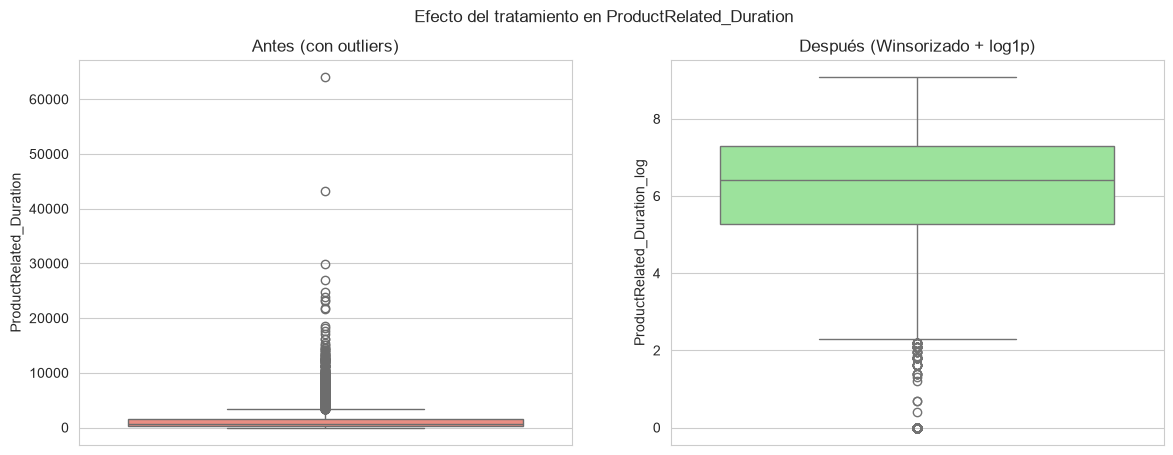

In [3]:
# Variables de duración a transformar
cols_duracion = ['Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration']

# Copia para no modificar la original
df_trans = df_clean.copy()

for col in cols_duracion:
    # 1. Calcular percentil 99
    p99 = df_trans[col].quantile(0.99)
    
    # 2. Winsorizar (recortar)
    df_trans[col] = np.clip(df_trans[col], a_min=None, a_max=p99)
    
    # 3. Aplicar log1p y crear nueva columna
    df_trans[f'{col}_log'] = np.log1p(df_trans[col])

# Visualizar el cambio (antes vs después)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(y=df_clean['ProductRelated_Duration'], ax=axes[0], color='salmon')
axes[0].set_title('Antes (con outliers)')
sns.boxplot(y=df_trans['ProductRelated_Duration_log'], ax=axes[1], color='lightgreen')
axes[1].set_title('Después (Winsorizado + log1p)')
plt.suptitle('Efecto del tratamiento en ProductRelated_Duration')
plt.show()

## 3. Alta cardinalidad (Categorías raras -> "Otros")
Variables como `Browser` o `TrafficType` tienen decenas de categorías, pero la mayoría tienen una frecuencia menor al 1%. 
Agruparlas en "Otros" reduce la dimensionalidad (evita la "maldición de la dimensionalidad"), mejora el rendimiento de los modelos y evita reglas basura en Apriori. Antes de agrupar, analizamos si las categorías raras esconden una alta tasa de compra (`Revenue == True`).

In [4]:
umbral = 0.01 # 1%
cols_alta_card = ['OperatingSystems', 'Browser', 'Region', 'TrafficType']

for col in cols_alta_card:
    print(f"\n--- Análisis de {col} ---")
    frecuencias = df_trans[col].value_counts(normalize=True)
    raras = frecuencias[frecuencias < umbral].index
    
    print(f"Categorías con <1%: {len(raras)} de {df_trans[col].nunique()}")
    
    # Revisar si alguna categoría rara destaca en compras
    if len(raras) > 0:
        compras_raras = df_trans[df_trans[col].isin(raras)]['Revenue'].mean()
        compras_totales = df_trans['Revenue'].mean()
        print(f"Tasa compra en categorías raras: {compras_raras:.4f} vs Global: {compras_totales:.4f}")
    
    # Agrupar en "Otros"
    df_trans[col] = df_trans[col].apply(lambda x: x if x not in raras else 'Otros')
    print(f"Nuevas categorías en {col}: {df_trans[col].nunique()}")


--- Análisis de OperatingSystems ---
Categorías con <1%: 4 de 8
Tasa compra en categorías raras: 0.1963 vs Global: 0.1563
Nuevas categorías en OperatingSystems: 5

--- Análisis de Browser ---
Categorías con <1%: 6 de 13
Tasa compra en categorías raras: 0.1366 vs Global: 0.1563
Nuevas categorías en Browser: 8

--- Análisis de Region ---
Categorías con <1%: 0 de 9
Nuevas categorías en Region: 9

--- Análisis de TrafficType ---
Categorías con <1%: 9 de 20
Tasa compra en categorías raras: 0.1227 vs Global: 0.1563
Nuevas categorías en TrafficType: 12


## 4. Codificación, Feature Engineering y Split
- **Variables Derivadas:** Adaptamos el requerimiento del PDF (1.3) al e-commerce. Crearemos:
  1. `Tiempo_promedio_pagina`: Tiempo total / Total de páginas visitadas.
  2. `Es_compra_potencial`: 1 si `PageValues > 0`, 0 en caso contrario.
  3. `Ratio_productos`: Proporción de páginas de productos sobre el total.
- **Codificación:** One-Hot para `Month`, `VisitorType` y las agrupadas en "Otros". 
- **Data Leakage:** Haremos el `train_test_split` **ANTES** de escalar los datos. La media y desviación estándar se calcularán solo con `X_train` y se aplicarán a `X_test`.

In [5]:
# 1. Variables Derivadas
total_paginas = df_trans['Administrative'] + df_trans['Informational'] + df_trans['ProductRelated']
# Evitar división por cero
total_paginas = total_paginas.replace(0, 1) 

df_trans['Tiempo_promedio_pagina'] = (df_trans['Administrative_Duration'] + 
                                       df_trans['Informational_Duration'] + 
                                       df_trans['ProductRelated_Duration']) / total_paginas

df_trans['Es_compra_potencial'] = (df_trans['PageValues'] > 0).astype(int)
df_trans['Ratio_productos'] = df_trans['ProductRelated'] / total_paginas

# 2. Codificación
# Convertir booleanos a 0/1
df_trans['Weekend'] = df_trans['Weekend'].astype(int)
df_trans['Revenue'] = df_trans['Revenue'].astype(int)

# One-Hot Encoding para categóricas (Month, VisitorType y las de alta cardinalidad)
cols_to_encode = ['Month', 'VisitorType'] + cols_alta_card
df_encoded = pd.get_dummies(df_trans, columns=cols_to_encode, drop_first=True)

print("Shape tras encoding:", df_encoded.shape)

Shape tras encoding: (12205, 59)


In [6]:
# 3. Separar X (features) e y (target)
X = df_encoded.drop(columns=['Revenue'])
y = df_encoded['Revenue']

# 4. Split estratificado (mantiene la proporción 85/15 de Revenue)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# 5. Escalado (Solo modelos que lo requieren)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convertir a DataFrames de nuevo para conservar nombres de columnas
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns)

Train: (9764, 58), Test: (2441, 58)


In [7]:
# Guardar Train/Test para modelos supervisados (Clasificación/Regresión)
X_train_scaled_df.to_csv('../data/processed/X_train_scaled.csv', index=False)
X_test_scaled_df.to_csv('../data/processed/X_test_scaled.csv', index=False)
y_train.to_csv('../data/processed/y_train.csv', index=False)
y_test.to_csv('../data/processed/y_test.csv', index=False)

# Guardar dataset completo SIN escalar (útil para Apriori, Árboles y reporte)
df_encoded.to_csv('../data/processed/dataset_full_encoded.csv', index=False)

print("¡Datasets guardados exitosamente en data/processed/!")

¡Datasets guardados exitosamente en data/processed/!
